#Strategic Techniques CA1 - Bike Sharing

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from scipy.stats import binom, poisson, norm

In [3]:
hour = pd.read_csv('hour.csv')
day = pd.read_csv('day.csv')

In [4]:
hour.head()

,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,0,6,0,1,0.24,0.2879,0.81,0.0,3,13,16
1,2,2011-01-01,1,0,1,1,0,6,0,1,0.22,0.2727,0.80,0.0,8,32,40
2,3,2011-01-01,1,0,1,2,0,6,0,1,0.22,0.2727,0.80,0.0,5,27,32
3,4,2011-01-01,1,0,1,3,0,6,0,1,0.24,0.2879,0.75,0.0,3,10,13
4,5,2011-01-01,1,0,1,4,0,6,0,1,0.24,0.2879,0.75,0.0,0,1,1


In [5]:
hour.shape

(17379, 17)

In [6]:
day = pd.read_csv('day.csv')

In [7]:
day.head()

,instant,dteday,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,6,0,2,0.344167,0.363625,0.805833,0.160446,331,654,985
1,2,2011-01-02,1,0,1,0,0,0,2,0.363478,0.353739,0.696087,0.248539,131,670,801
2,3,2011-01-03,1,0,1,0,1,1,1,0.196364,0.189405,0.437273,0.248309,120,1229,1349
3,4,2011-01-04,1,0,1,0,2,1,1,0.200000,0.212122,0.590435,0.160296,108,1454,1562
4,5,2011-01-05,1,0,1,0,3,1,1,0.226957,0.229270,0.436957,0.186900,82,1518,1600


In [8]:
day.shape

(731, 16)

In [9]:
print('Hourly data:', hour.shape)
print('Daily data:', day.shape)
print(hour.head())

Hourly data: (17379, 17)
Daily data: (731, 16)
   instant      dteday  season  yr  mnth  hr  holiday  weekday  workingday  \
0        1  2011-01-01       1   0     1   0        0        6           0   
1        2  2011-01-01       1   0     1   1        0        6           0   
2        3  2011-01-01       1   0     1   2        0        6           0   
3        4  2011-01-01       1   0     1   3        0        6           0   
4        5  2011-01-01       1   0     1   4        0        6           0   

   weathersit  temp   atemp   hum  windspeed  casual  registered  cnt  
0           1  0.24  0.2879  0.81        0.0       3          13   16  
1           1  0.22  0.2727  0.80        0.0       8          32   40  
2           1  0.22  0.2727  0.80        0.0       5          27   32  
3           1  0.24  0.2879  0.75        0.0       3          10   13  
4           1  0.24  0.2879  0.75        0.0       0           1    1  


In [10]:
print('Missing values:', hour.isnull().sum().sum())
print('Duplicate date/hour rows:', hour.duplicated(['dteday', 'hr']).sum())
print('Incorrect totals:', (hour['cnt'] != hour['casual'] + hour['registered']).sum())
print('Missing values in daily file:', day.isnull().sum().sum())

Missing values: 0
Duplicate date/hour rows: 0
Incorrect totals: 0
Missing values in daily file: 0


In [11]:
hour.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 17379 entries, 0 to 17378
Data columns (total 17 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   instant     17379 non-null  int64  
 1   dteday      17379 non-null  object 
 2   season      17379 non-null  int64  
 3   yr          17379 non-null  int64  
 4   mnth        17379 non-null  int64  
 5   hr          17379 non-null  int64  
 6   holiday     17379 non-null  int64  
 7   weekday     17379 non-null  int64  
 8   workingday  17379 non-null  int64  
 9   weathersit  17379 non-null  int64  
 10  temp        17379 non-null  float64
 11  atemp       17379 non-null  float64
 12  hum         17379 non-null  float64
 13  windspeed   17379 non-null  float64
 14  casual      17379 non-null  int64  
 15  registered  17379 non-null  int64  
 16  cnt         17379 non-null  int64  
dtypes: float64(4), int64(12), object(1)
memory usage: 2.3+ MB


In [12]:
print('Missing values:')
print(hour.isnull().sum())
print('Duplicate date-hour records:', hour.duplicated(['dteday', 'hr']).sum())
print('Incorrect rental totals:', (hour['casual'] + hour['registered'] != hour['cnt']).sum())

Missing values:
instant       0
dteday        0
season        0
yr            0
mnth          0
hr            0
holiday       0
weekday       0
workingday    0
weathersit    0
temp          0
atemp         0
hum           0
windspeed     0
casual        0
registered    0
cnt           0
dtype: int64
Duplicate date-hour records: 0
Incorrect rental totals: 0


In [13]:
hour['dteday'] = pd.to_datetime(hour['dteday'])
day['dteday'] = pd.to_datetime(day['dteday'])
hour['temp_c'] = hour['temp'] * 41
hour['hum_pct'] = hour['hum'] * 100
hour['wind_kmh'] = hour['windspeed'] * 67  # original scale; units not specified in Readme
hour[['cnt', 'casual', 'registered', 'temp_c', 'hum_pct', 'wind_kmh']].describe().round(2)

,cnt,casual,registered,temp_c,hum_pct,wind_kmh
count,17379.00,17379.00,17379.00,17379.00,17379.00,17379.00
mean,189.46,35.68,153.79,20.38,62.72,12.74
std,181.39,49.31,151.36,7.89,19.29,8.20
min,1.00,0.00,0.00,0.82,0.00,0.00
25%,40.00,4.00,34.00,13.94,48.00,7.00
50%,142.00,17.00,115.00,20.50,63.00,13.00
75%,281.00,48.00,220.00,27.06,78.00,17.00
max,977.00,367.00,886.00,41.00,100.00,57.00


In [14]:
print('Mean rentals:', round(hour['cnt'].mean(), 2))
print('Median rentals:', hour['cnt'].median())
print('Mode rentals:', hour['cnt'].mode()[0])
print('Standard deviation:', round(hour['cnt'].std(), 2))
print('Variance:', round(hour['cnt'].var(), 2))
print('Skewness:', round(hour['cnt'].skew(), 2))
print('Kurtosis:', round(hour['cnt'].kurt(), 2))

Mean rentals: 189.46
Median rentals: 142.0
Mode rentals: 5
Standard deviation: 181.39
Variance: 32901.46
Skewness: 1.28
Kurtosis: 1.42


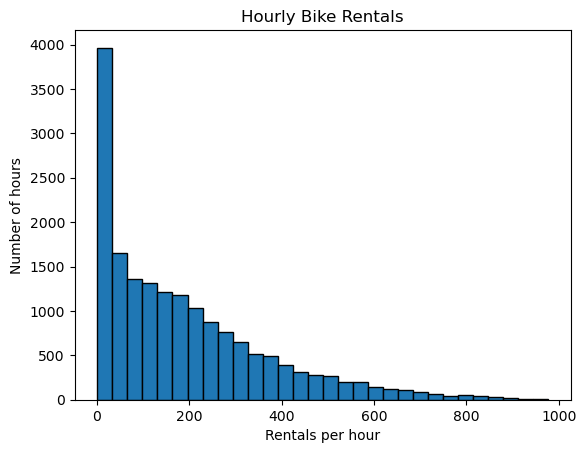

In [15]:
plt.hist(hour['cnt'], bins=30, edgecolor='black')
plt.title('Hourly Bike Rentals')
plt.xlabel('Rentals per hour')
plt.ylabel('Number of hours')
plt.show()

#Histogram to see the overall shape of rental counts. A long right tail means some hours are much busier than most.

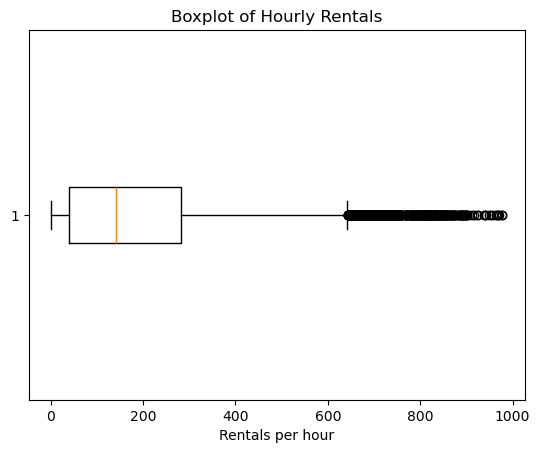

In [17]:
plt.boxplot(hour['cnt'], vert=False)
plt.title('Boxplot of Hourly Rentals')
plt.xlabel('Rentals per hour')
plt.show()

#A boxplot shows the median, spread and unusual high rental values.

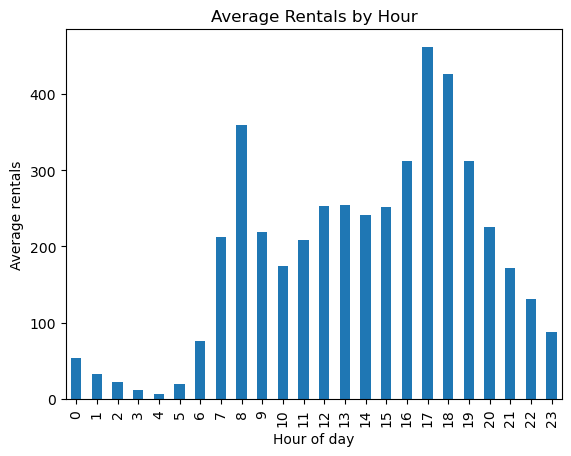

In [19]:
hour.groupby('hr')['cnt'].mean().plot(kind='bar')
plt.title('Average Rentals by Hour')
plt.xlabel('Hour of day')
plt.ylabel('Average rentals')
plt.show()

#Compare the average rental count at each hour. Different hours are not equally busy, which matters for the Poisson assumptions.

#Compare average rentals across weather groups.

In [22]:
hour_daily = hour.groupby('dteday')['cnt'].sum()
daily_check = day.set_index('dteday')['cnt']
print('Days with different totals:', (hour_daily != daily_check).sum())
print('Total rentals:', hour['cnt'].sum())

Days with different totals: 0
Total rentals: 3292679


#Binomial distribution

In [24]:
hour['high_demand'] = (hour['cnt'] > 300).astype(int)
p = hour['high_demand'].mean()
n = 10
print('Observed high-demand rate:', round(p, 4))
print('P(exactly 3 high-demand hours out of 10):', round(binom.pmf(3, n, p), 4))
print('P(at least 3 high-demand hours out of 10):', round(1 - binom.cdf(2, n, p), 4))
print('Expected successes:', round(n * p, 2))

Observed high-demand rate: 0.2239
P(exactly 3 high-demand hours out of 10): 0.2284
P(at least 3 high-demand hours out of 10): 0.395
Expected successes: 2.24


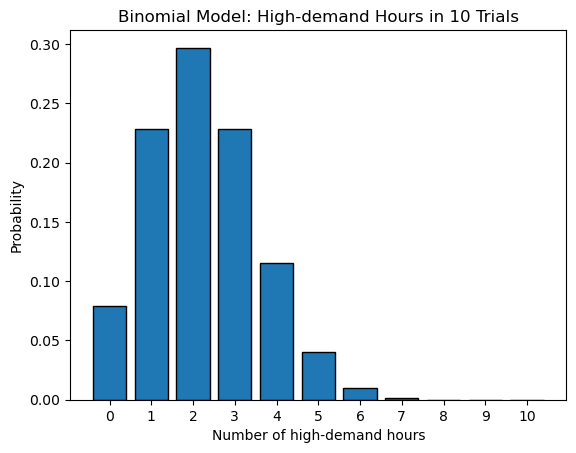

In [25]:
x = np.arange(0, 11)
plt.bar(x, binom.pmf(x, 10, p), edgecolor='black')
plt.title('Binomial Model: High-demand Hours in 10 Trials')
plt.xlabel('Number of high-demand hours')
plt.ylabel('Probability')
plt.xticks(x)
plt.show()

For 100 hours, expected successes: 22.39
np: 22.39
n(1-p): 77.61


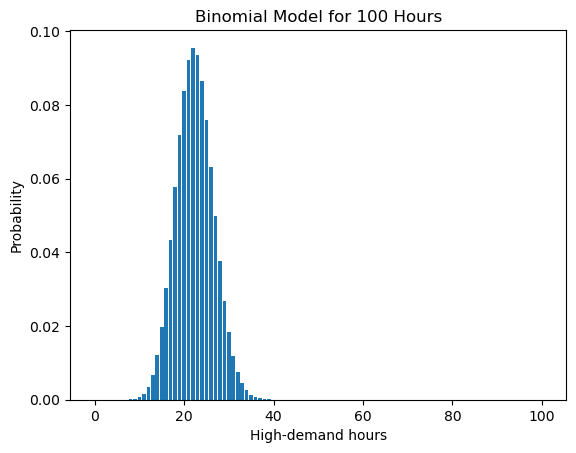

In [26]:
n_large = 100
print('For 100 hours, expected successes:', round(n_large*p, 2))
print('np:', round(n_large*p, 2))
print('n(1-p):', round(n_large*(1-p), 2))
x = np.arange(0, 101)
plt.bar(x, binom.pmf(x, n_large, p))
plt.title('Binomial Model for 100 Hours')
plt.xlabel('High-demand hours')
plt.ylabel('Probability')
plt.show()
#For a larger number of trials, the expected number of successes increases with n

#Poisson distribution

In [28]:
lam = hour['cnt'].mean()
print('Lambda (mean hourly rentals):', round(lam, 2))
print('Observed variance:', round(hour['cnt'].var(), 2))
print('Variance / mean:', round(hour['cnt'].var()/lam, 2))
print('Poisson P(exactly 200 rentals):', round(poisson.pmf(200, lam), 5))
print('Poisson P(at most 200 rentals):', round(poisson.cdf(200, lam), 4))

Lambda (mean hourly rentals): 189.46
Observed variance: 32901.46
Variance / mean: 173.66
Poisson P(exactly 200 rentals): 0.02115
Poisson P(at most 200 rentals): 0.7899


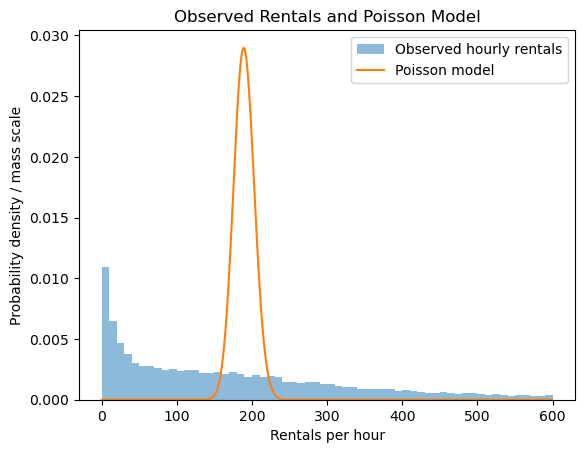

In [29]:
x = np.arange(0, 600)
plt.hist(hour['cnt'], bins=60, range=(0, 600), density=True, alpha=0.5, label='Observed hourly rentals')
plt.plot(x, poisson.pmf(x, lam), label='Poisson model')
plt.title('Observed Rentals and Poisson Model')
plt.xlabel('Rentals per hour')
plt.ylabel('Probability density / mass scale')
plt.legend()
plt.show()

#Normal distribution

In [31]:
mu = hour['temp_c'].mean()
sd = hour['temp_c'].std()
print('Mean temperature:', round(mu, 2), 'C')
print('Standard deviation:', round(sd, 2), 'C')
print('Skewness:', round(hour['temp_c'].skew(), 2))
print('Kurtosis:', round(hour['temp_c'].kurt(), 2))
print('Normal model P(temp < 10 C):', round(norm.cdf(10, mu, sd), 4))
print('Normal model P(10 C < temp < 20 C):', round(norm.cdf(20, mu, sd)-norm.cdf(10, mu, sd), 4))
print('Actual fraction temp < 10 C:', round((hour['temp_c'] < 10).mean(), 4))

Mean temperature: 20.38 C
Standard deviation: 7.89 C
Skewness: -0.01
Kurtosis: -0.94
Normal model P(temp < 10 C): 0.0944
Normal model P(10 C < temp < 20 C): 0.3866
Actual fraction temp < 10 C: 0.1158


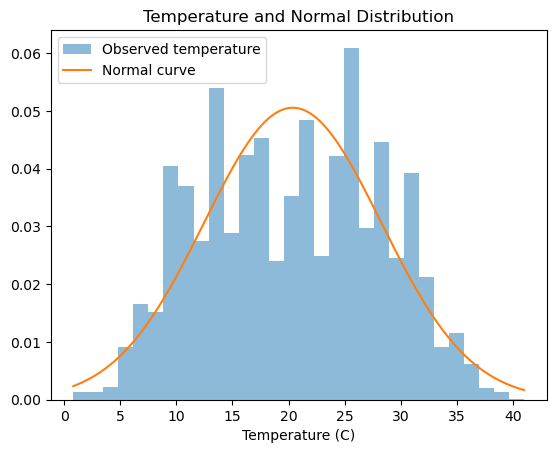

In [32]:
plt.hist(hour['temp_c'], bins=30, density=True, alpha=0.5, label='Observed temperature')
x = np.linspace(hour['temp_c'].min(), hour['temp_c'].max(), 200)
plt.plot(x, norm.pdf(x, mu, sd), label='Normal curve')
plt.title('Temperature and Normal Distribution')
plt.xlabel('Temperature (C)')
plt.legend()
plt.show()

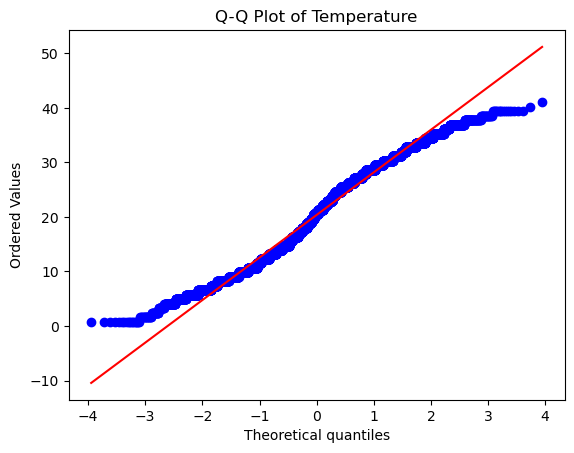

In [33]:
stats.probplot(hour['temp_c'], dist='norm', plot=plt)
plt.title('Q-Q Plot of Temperature')
plt.show()

#A Poisson distribution with a large mean can also have a bell-shaped approximation, but the real rental data may still not be normal because the demand rate changes across hours. We should check the actual histogram and assumptions, not rely on sample size alone.

In [35]:
print('Summary for report')
print('Hourly records:', len(hour))
print('Daily records:', len(day))
print('Mean hourly rentals:', round(hour['cnt'].mean(), 2))
print('High demand (>300) proportion:', round(p, 4))
print('Poisson mean:', round(lam, 2))
print('Poisson variance/mean:', round(hour['cnt'].var()/lam, 2))
print('Mean temperature (C):', round(mu, 2))
print('Temperature skewness:', round(hour['temp_c'].skew(), 2))

Summary for report
Hourly records: 17379
Daily records: 731
Mean hourly rentals: 189.46
High demand (>300) proportion: 0.2239
Poisson mean: 189.46
Poisson variance/mean: 173.66
Mean temperature (C): 20.38
Temperature skewness: -0.01
